In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [ ]:
dataset = pd.read_csv("../data/encoding/data_new.csv")

diagnosis_variables = []
with open("../data/encoding/diagnosis_new.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/encoding/treatment_new.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

'''surgery_variables = []
with open("../data/encoding/surgery.txt", "r") as file:
    for line in file:
        surgery_variables.append(line.strip())

cols_to_remove = ['Final pathology', 'Final recommendations to patient']

removed = []
for c in cols_to_remove:
    if c in diagnosis_variables:
        diagnosis_variables.remove(c)
        removed.append(c)

# Also drop these columns from the dataframe so they won't appear in survival_dataset
if removed:
    dataset = dataset.drop(columns=removed, errors='ignore')'''

feature_columns = treatment_variables + diagnosis_variables #+ surgery_variables

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [7]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Test events: 6.0


In [8]:
subsampling = survival_dataset.iloc[train_index].copy()

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

In [9]:
# Scale features for FINAL MODEL training and test evaluation
# NOTE: This scaling is ONLY for final model training after CV hyperparameter selection
# During CV, scaling happens INSIDE each fold (see cox_cross_validation function)
# Without scaling, L1 penalty affects features with different ranges unequally

scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# # convert scaled arrays back to DataFrame (preserve original columns and indices)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)

In [10]:
l1_ratio = 1.0
model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)
alphas = np.logspace(-4, -2, 20)
(alphas)
list_alphas = alphas.tolist()
alphas = pd.DataFrame(list_alphas, columns=['Alphas'])

In [14]:
# Fine-tune the number of controls per case with multiple alpha values
print("=== OPTIMIZING NUMBER OF CONTROLS PER CASE (WITH MULTIPLE ALPHAS) ===")

# Test different numbers of controls per case
controls_per_case_options = [3, 4, 5, 7, 10]
# Define alpha range for testing
alpha_range = np.logspace(-2, 1, 10)  # 10 alpha values to test
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

# Store results: controls_results[n_controls][alpha] = results_df
controls_results = {}

for n_controls in controls_per_case_options:
    print(f"\n{'='*70}")
    print(f"Testing {n_controls} controls per case with {len(alpha_range)} alpha values...")
    print(f"{'='*70}")
    
    controls_results[n_controls] = {}
    
    for alpha in alpha_range:
        print(f"  Alpha: {alpha:.6f}", end=" ")
        
        results_df = subsampling_cross_validation(
            subsampling, x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, 
            metrics=metrics, n_controls_per_case=n_controls, feature_columns=feature_columns, scaler=StandardScaler()
        )
        controls_results[n_controls][alpha] = results_df
        
        # Print inline summary
        print(f"→ C-Idx: {results_df.loc['Mean', 'c-index']:.4f}, IPCW: {results_df.loc['Mean', 'c-index-ipcw']:.4f}, Brier: {results_df.loc['Mean', 'int-brier-score']:.4f}")
    
    # Find and display best 3 alphas for this n_controls
    print(f"\n  Best 3 alphas for {n_controls} controls per case:")
    
    # Best for C-Index
    cindex_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index']) for alpha in alpha_range]
    cindex_scores.sort(key=lambda x: x[1], reverse=True)
    print(f"    C-Index: α={cindex_scores[0][0]:.6f} ({cindex_scores[0][1]:.4f}), "
          f"α={cindex_scores[1][0]:.6f} ({cindex_scores[1][1]:.4f}), "
          f"α={cindex_scores[2][0]:.6f} ({cindex_scores[2][1]:.4f})")
    
    # Best for IPCW C-Index
    ipcw_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index-ipcw']) for alpha in alpha_range]
    ipcw_scores.sort(key=lambda x: x[1], reverse=True)
    print(f"    IPCW C-Index: α={ipcw_scores[0][0]:.6f} ({ipcw_scores[0][1]:.4f}), "
          f"α={ipcw_scores[1][0]:.6f} ({ipcw_scores[1][1]:.4f}), "
          f"α={ipcw_scores[2][0]:.6f} ({ipcw_scores[2][1]:.4f})")
    
    # Best for Brier Score (lower is better)
    brier_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'int-brier-score']) for alpha in alpha_range]
    brier_scores.sort(key=lambda x: x[1])
    print(f"    Brier Score: α={brier_scores[0][0]:.6f} ({brier_scores[0][1]:.4f}), "
          f"α={brier_scores[1][0]:.6f} ({brier_scores[1][1]:.4f}), "
          f"α={brier_scores[2][0]:.6f} ({brier_scores[2][1]:.4f})")

print("\n" + "="*70)
print("Controls per case optimization with multiple alphas completed!")
print("="*70)

=== OPTIMIZING NUMBER OF CONTROLS PER CASE (WITH MULTIPLE ALPHAS) ===

Testing 3 controls per case with 10 alpha values...
  Alpha: 0.010000 ⚠️  Info: 6 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [ 1 26 27 34 39 45]
   Features after removal: 40 (removed 6)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


ValueError: Input estimate contains NaN.

In [35]:
# Create summaries for controls per case optimization (with best alpha for each)
print("=== CONTROLS PER CASE OPTIMIZATION RESULTS ===")
print("(Showing best performance across all tested alphas)\n")

controls_cindex_summary = []
controls_ipcw_summary = []
controls_brier_summary = []

# Store best alpha information for each n_controls and metric
best_configs = {}

for n_controls in controls_per_case_options:
    best_configs[n_controls] = {}
    
    # Find best alpha for each metric
    best_cindex = max([(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index']) 
                       for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    best_ipcw = max([(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index-ipcw']) 
                     for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    best_brier = min([(alpha, controls_results[n_controls][alpha].loc['Mean', 'int-brier-score']) 
                      for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    
    best_configs[n_controls]['c-index'] = {'alpha': best_cindex[0], 'score': best_cindex[1]}
    best_configs[n_controls]['c-index-ipcw'] = {'alpha': best_ipcw[0], 'score': best_ipcw[1]}
    best_configs[n_controls]['int-brier-score'] = {'alpha': best_brier[0], 'score': best_brier[1]}
    
    # Get std from the best alpha results
    controls_cindex_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_cindex[0],
        'Mean': best_cindex[1],
        'Std': controls_results[n_controls][best_cindex[0]].loc['Std', 'c-index']
    })
    controls_ipcw_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_ipcw[0],
        'Mean': best_ipcw[1],
        'Std': controls_results[n_controls][best_ipcw[0]].loc['Std', 'c-index-ipcw']
    })
    controls_brier_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_brier[0],
        'Mean': best_brier[1],
        'Std': controls_results[n_controls][best_brier[0]].loc['Std', 'int-brier-score']
    })

controls_cindex_df = pd.DataFrame(controls_cindex_summary)
controls_ipcw_df = pd.DataFrame(controls_ipcw_summary)
controls_brier_df = pd.DataFrame(controls_brier_summary)

print("C-Index Results (with best alpha for each):")
print(controls_cindex_df.sort_values('Mean', ascending=False).to_string(index=False))
print(f"Best overall: {controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'N_Controls']} controls per case "
      f"(α={controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'Best_Alpha']:.6f})")

print("\nIPCW C-Index Results (with best alpha for each):")
print(controls_ipcw_df.sort_values('Mean', ascending=False).to_string(index=False))
print(f"Best overall: {controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'N_Controls']} controls per case "
      f"(α={controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'Best_Alpha']:.6f})")

print("\nBrier Score Results (lower is better, with best alpha for each):")
print(controls_brier_df.sort_values('Mean', ascending=True).to_string(index=False))
print(f"Best overall: {controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'N_Controls']} controls per case "
      f"(α={controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'Best_Alpha']:.6f})")

=== CONTROLS PER CASE OPTIMIZATION RESULTS ===
(Showing best performance across all tested alphas)

C-Index Results (with best alpha for each):
 N_Controls  Best_Alpha     Mean      Std
          3         0.1 0.688991 0.113874
          4         0.1 0.635188 0.074054
          5         0.1 0.601820 0.121493
          7         0.1 0.590574 0.105116
         10         0.1 0.500000 0.000000
Best overall: 3 controls per case (α=0.100000)

IPCW C-Index Results (with best alpha for each):
 N_Controls  Best_Alpha     Mean      Std
          4    0.100000 0.609189 0.070103
          3    0.100000 0.596684 0.017835
          5    0.129155 0.570677 0.083234
          7    0.100000 0.547278 0.070178
         10    0.100000 0.500000 0.000000
Best overall: 4 controls per case (α=0.100000)

Brier Score Results (lower is better, with best alpha for each):
 N_Controls  Best_Alpha     Mean      Std
         10    0.100000 0.014006 0.001911
          7    0.129155 0.016038 0.002013
          5    0

In [13]:
# Fine-tune the number of controls per case
print("=== OPTIMIZING NUMBER OF CONTROLS PER CASE ===")

# Test different numbers of controls per case
controls_per_case_options = [1, 3, 4, 5, 7, 10, 15]
fixed_alpha = 0.05  # Use a fixed alpha for this optimization
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

# Define scaling methods (StandardScaler removed - causes issues with constant features)
scaling_methods = {
    'no_scaling': None,
    'minmax': MinMaxScaler()
}

controls_results = {}

for scaling_name, scaler in scaling_methods.items():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}")
    
    controls_results[scaling_name] = {}
    
    for n_controls in controls_per_case_options:
        print(f"Testing {n_controls} controls per case...")
        
        results_df = subsampling_cross_validation(
            subsampling, x_train, y_train, sgkf_1, alpha=fixed_alpha, l1_ratio=l1_ratio, 
            metrics=metrics, n_controls_per_case=n_controls, feature_columns=feature_columns,
            scaler=scaler
        )
        controls_results[scaling_name][n_controls] = results_df
        
        # Print quick summary
        print(f"  C-Index: {results_df.loc['Mean', 'c-index']:.4f} ± {results_df.loc['Std', 'c-index']:.4f}")
        print(f"  IPCW C-Index: {results_df.loc['Mean', 'c-index-ipcw']:.4f} ± {results_df.loc['Std', 'c-index-ipcw']:.4f}")
        print(f"  Brier Score: {results_df.loc['Mean', 'int-brier-score']:.4f} ± {results_df.loc['Std', 'int-brier-score']:.4f}")
        print()

print("\n" + "="*70)
print("Controls per case optimization completed for all scaling methods!")
print("="*70)

=== OPTIMIZING NUMBER OF CONTROLS PER CASE ===

SCALING METHOD: NO SCALING
Testing 1 controls per case...
  C-Index: 0.7670 ± 0.0640
  IPCW C-Index: 0.6811 ± 0.0618
  Brier Score: 0.0712 ± 0.0234

Testing 3 controls per case...
  C-Index: 0.7184 ± 0.1338
  IPCW C-Index: 0.6575 ± 0.0556
  Brier Score: 0.0353 ± 0.0171

Testing 4 controls per case...
  C-Index: 0.6752 ± 0.1211
  IPCW C-Index: 0.6213 ± 0.0313
  Brier Score: 0.0225 ± 0.0071

Testing 5 controls per case...
  C-Index: 0.6966 ± 0.0931
  IPCW C-Index: 0.6627 ± 0.0593
  Brier Score: 0.0207 ± 0.0054

Testing 7 controls per case...
  C-Index: 0.6994 ± 0.1114
  IPCW C-Index: 0.6512 ± 0.0407
  Brier Score: 0.0165 ± 0.0019

Testing 10 controls per case...
  C-Index: 0.6747 ± 0.1153
  IPCW C-Index: 0.6152 ± 0.0667
  Brier Score: 0.0152 ± 0.0033

Testing 15 controls per case...
  C-Index: 0.6669 ± 0.1145
  IPCW C-Index: 0.6003 ± 0.0631
  Brier Score: 0.0140 ± 0.0031


SCALING METHOD: MINMAX
Testing 1 controls per case...
  C-Index: 0.7

c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)


  C-Index: 0.5760 ± 0.0887
  IPCW C-Index: 0.5477 ± 0.0590
  Brier Score: 0.0183 ± 0.0020

Testing 7 controls per case...


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)


  C-Index: 0.5000 ± 0.0000
  IPCW C-Index: 0.5000 ± 0.0000
  Brier Score: 0.0160 ± 0.0020

Testing 10 controls per case...


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)


  C-Index: 0.5000 ± 0.0000
  IPCW C-Index: 0.5000 ± 0.0000
  Brier Score: 0.0140 ± 0.0019

Testing 15 controls per case...


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train_sub_scaled, y_train_sub)


  C-Index: 0.5000 ± 0.0000
  IPCW C-Index: 0.5000 ± 0.0000
  Brier Score: 0.0135 ± 0.0029


Controls per case optimization completed for all scaling methods!


In [14]:
# Create summaries for controls per case optimization (comparing all scaling methods)
print("=== CONTROLS PER CASE OPTIMIZATION RESULTS (ALL SCALING METHODS) ===\n")

for scaling_name in scaling_methods.keys():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}")
    
    controls_cindex_summary = []
    controls_ipcw_summary = []
    controls_brier_summary = []

    for n_controls, df in controls_results[scaling_name].items():
        controls_cindex_summary.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'c-index'],
            'Std': df.loc['Std', 'c-index']
        })
        controls_ipcw_summary.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'c-index-ipcw'],
            'Std': df.loc['Std', 'c-index-ipcw']
        })
        controls_brier_summary.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'int-brier-score'],
            'Std': df.loc['Std', 'int-brier-score']
        })

    controls_cindex_df = pd.DataFrame(controls_cindex_summary)
    controls_ipcw_df = pd.DataFrame(controls_ipcw_summary)
    controls_brier_df = pd.DataFrame(controls_brier_summary)

    print("\nC-Index Results:")
    print(controls_cindex_df.sort_values('Mean', ascending=False))
    print(f"Best: {controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'N_Controls']} controls per case")

    print("\nIPCW C-Index Results:")
    print(controls_ipcw_df.sort_values('Mean', ascending=False))
    print(f"Best: {controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'N_Controls']} controls per case")

    print("\nBrier Score Results (lower is better):")
    print(controls_brier_df.sort_values('Mean', ascending=True))
    print(f"Best: {controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'N_Controls']} controls per case")
    
    # Store for later comparison
    if scaling_name == 'no_scaling':
        controls_cindex_df_no = controls_cindex_df
        controls_ipcw_df_no = controls_ipcw_df
        controls_brier_df_no = controls_brier_df
    elif scaling_name == 'standard':
        controls_cindex_df_std = controls_cindex_df
        controls_ipcw_df_std = controls_ipcw_df
        controls_brier_df_std = controls_brier_df
    elif scaling_name == 'minmax':
        controls_cindex_df_mm = controls_cindex_df
        controls_ipcw_df_mm = controls_ipcw_df
        controls_brier_df_mm = controls_brier_df

# Comparison across scaling methods
print("\n" + "="*70)
print("COMPARISON: BEST PERFORMANCE ACROSS SCALING METHODS")
print("="*70)

# For each metric, show which scaling method performed best
print("\nBest C-Index by scaling method:")
for scaling_name in scaling_methods.keys():
    best_controls = controls_results[scaling_name]
    best_perf = max([df.loc['Mean', 'c-index'] for df in best_controls.values()])
    best_n = [n for n, df in best_controls.items() if df.loc['Mean', 'c-index'] == best_perf][0]
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_perf:.4f} (n_controls={best_n})")

print("\nBest IPCW C-Index by scaling method:")
for scaling_name in scaling_methods.keys():
    best_controls = controls_results[scaling_name]
    best_perf = max([df.loc['Mean', 'c-index-ipcw'] for df in best_controls.values()])
    best_n = [n for n, df in best_controls.items() if df.loc['Mean', 'c-index-ipcw'] == best_perf][0]
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_perf:.4f} (n_controls={best_n})")

print("\nBest Brier Score by scaling method (lower is better):")
for scaling_name in scaling_methods.keys():
    best_controls = controls_results[scaling_name]
    best_perf = min([df.loc['Mean', 'int-brier-score'] for df in best_controls.values()])
    best_n = [n for n, df in best_controls.items() if df.loc['Mean', 'int-brier-score'] == best_perf][0]
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_perf:.4f} (n_controls={best_n})")

=== CONTROLS PER CASE OPTIMIZATION RESULTS (ALL SCALING METHODS) ===


SCALING METHOD: NO SCALING

C-Index Results:
   N_Controls      Mean       Std
0           1  0.767017  0.064021
1           3  0.718402  0.133822
4           7  0.699418  0.111397
3           5  0.696639  0.093057
2           4  0.675170  0.121100
5          10  0.674662  0.115292
6          15  0.666852  0.114497
Best: 1 controls per case

IPCW C-Index Results:
   N_Controls      Mean       Std
0           1  0.681126  0.061768
3           5  0.662736  0.059290
1           3  0.657468  0.055583
4           7  0.651182  0.040729
2           4  0.621268  0.031337
5          10  0.615164  0.066701
6          15  0.600331  0.063117
Best: 1 controls per case

Brier Score Results (lower is better):
   N_Controls      Mean       Std
6          15  0.013978  0.003058
5          10  0.015173  0.003323
4           7  0.016465  0.001933
3           5  0.020669  0.005368
2           4  0.022508  0.007052
1           3  0.0352

KeyError: 'standard'

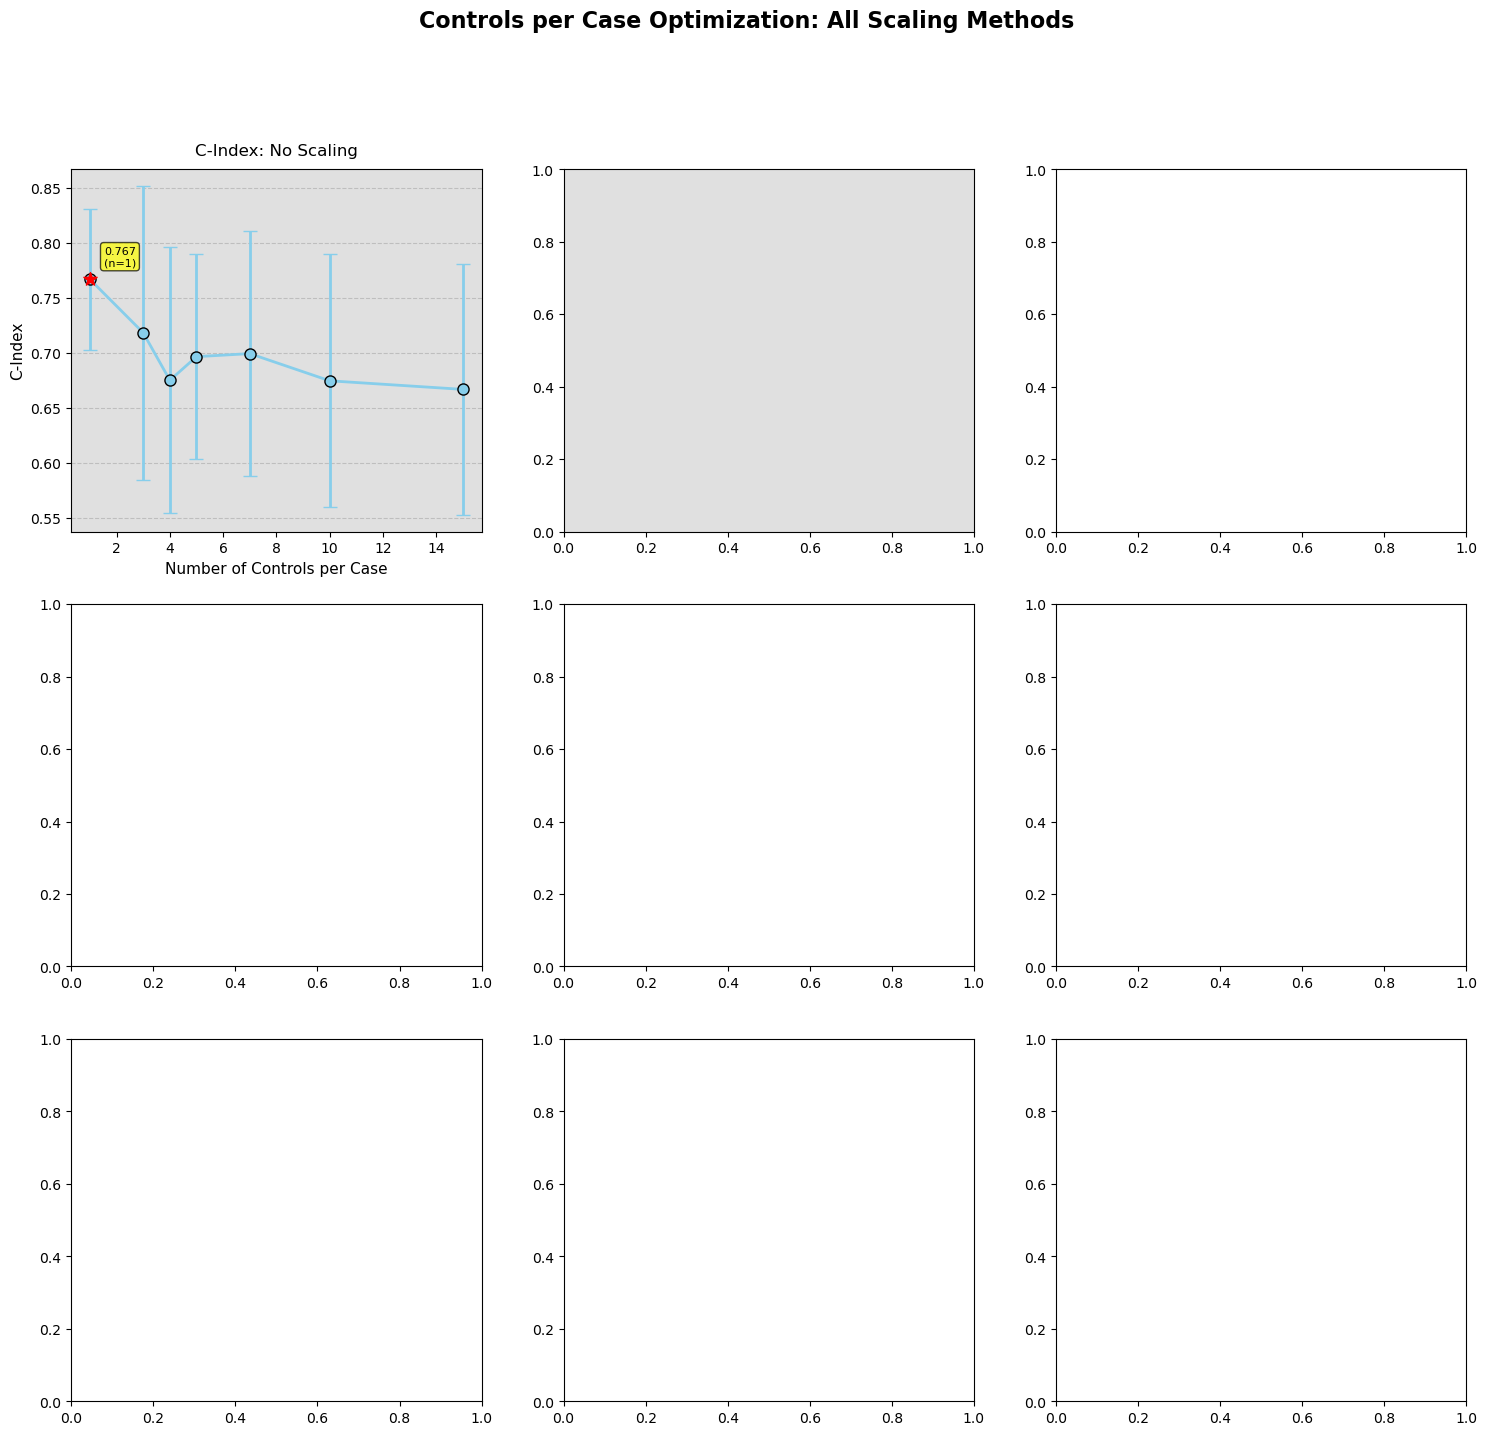

In [15]:
# Plot controls per case optimization results (comparing all scaling methods)
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
fig.patch.set_facecolor('None')
fig.suptitle('Controls per Case Optimization: All Scaling Methods', fontsize=16, fontweight='bold')

colors = {'no_scaling': 'skyblue', 'standard': 'salmon', 'minmax': 'lightgreen'}
labels = {'no_scaling': 'No Scaling', 'standard': 'Standard Scaling', 'minmax': 'MinMax Scaling'}

# Row 0: C-Index
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[0, idx]
    ax.set_facecolor('#e0e0e0')
    
    # Get data for this scaling method
    cindex_data = []
    for n_controls in controls_per_case_options:
        df = controls_results[scaling_name][n_controls]
        cindex_data.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'c-index'],
            'Std': df.loc['Std', 'c-index']
        })
    cindex_df = pd.DataFrame(cindex_data)
    
    ax.errorbar(cindex_df['N_Controls'], cindex_df['Mean'], 
                yerr=cindex_df['Std'], fmt='o-', capsize=5, color=color, 
                markeredgecolor='black', linewidth=2, markersize=8)
    ax.set_xlabel('Number of Controls per Case', fontsize=11)
    ax.set_ylabel('C-Index', fontsize=11)
    ax.set_title(f'C-Index: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point
    best_idx = cindex_df['Mean'].idxmax()
    best_controls = cindex_df.loc[best_idx, 'N_Controls']
    best_mean = cindex_df.loc[best_idx, 'Mean']
    ax.scatter(best_controls, best_mean, color='red', s=100, zorder=5, marker='*')
    ax.annotate(f'{best_mean:.3f}\n(n={int(best_controls)})', 
                xy=(best_controls, best_mean),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8)

# Row 1: IPCW C-Index
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[1, idx]
    ax.set_facecolor('#e0e0e0')
    
    # Get data for this scaling method
    ipcw_data = []
    for n_controls in controls_per_case_options:
        df = controls_results[scaling_name][n_controls]
        ipcw_data.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'c-index-ipcw'],
            'Std': df.loc['Std', 'c-index-ipcw']
        })
    ipcw_df = pd.DataFrame(ipcw_data)
    
    ax.errorbar(ipcw_df['N_Controls'], ipcw_df['Mean'], 
                yerr=ipcw_df['Std'], fmt='o-', capsize=5, color=color,
                markeredgecolor='black', linewidth=2, markersize=8)
    ax.set_xlabel('Number of Controls per Case', fontsize=11)
    ax.set_ylabel('IPCW C-Index', fontsize=11)
    ax.set_title(f'IPCW C-Index: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point
    best_idx = ipcw_df['Mean'].idxmax()
    best_controls = ipcw_df.loc[best_idx, 'N_Controls']
    best_mean = ipcw_df.loc[best_idx, 'Mean']
    ax.scatter(best_controls, best_mean, color='red', s=100, zorder=5, marker='*')
    ax.annotate(f'{best_mean:.3f}\n(n={int(best_controls)})', 
                xy=(best_controls, best_mean),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8)

# Row 2: Brier Score
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[2, idx]
    ax.set_facecolor('#e0e0e0')
    
    # Get data for this scaling method
    brier_data = []
    for n_controls in controls_per_case_options:
        df = controls_results[scaling_name][n_controls]
        brier_data.append({
            'N_Controls': n_controls,
            'Mean': df.loc['Mean', 'int-brier-score'],
            'Std': df.loc['Std', 'int-brier-score']
        })
    brier_df = pd.DataFrame(brier_data)
    
    ax.errorbar(brier_df['N_Controls'], brier_df['Mean'], 
                yerr=brier_df['Std'], fmt='o-', capsize=5, color=color,
                markeredgecolor='black', linewidth=2, markersize=8)
    ax.set_xlabel('Number of Controls per Case', fontsize=11)
    ax.set_ylabel('Integrated Brier Score', fontsize=11)
    ax.set_title(f'Brier Score: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point (minimum for Brier score)
    best_idx = brier_df['Mean'].idxmin()
    best_controls = brier_df.loc[best_idx, 'N_Controls']
    best_mean = brier_df.loc[best_idx, 'Mean']
    ax.scatter(best_controls, best_mean, color='red', s=100, zorder=5, marker='*')
    ax.annotate(f'{best_mean:.3f}\n(n={int(best_controls)})', 
                xy=(best_controls, best_mean),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# Analyze the trade-offs and select optimal number of controls FOR EACH SCALING METHOD
print("=== TRADE-OFF ANALYSIS (ALL SCALING METHODS) ===\n")

best_configs_by_scaling = {}

for scaling_name in scaling_methods.keys():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}")
    
    # Get best values for each metric for this scaling method
    best_n_cindex = max(controls_results[scaling_name].items(), 
                       key=lambda x: x[1].loc['Mean', 'c-index'])[0]
    best_n_ipcw = max(controls_results[scaling_name].items(), 
                     key=lambda x: x[1].loc['Mean', 'c-index-ipcw'])[0]
    best_n_brier = min(controls_results[scaling_name].items(), 
                      key=lambda x: x[1].loc['Mean', 'int-brier-score'])[0]
    
    print(f"Best for C-Index: {best_n_cindex} controls per case")
    print(f"Best for IPCW C-Index: {best_n_ipcw} controls per case")
    print(f"Best for Brier Score: {best_n_brier} controls per case")
    
    # Check if there's a consensus
    from collections import Counter
    best_choices = [best_n_cindex, best_n_ipcw, best_n_brier]
    consensus = Counter(best_choices).most_common(1)[0]
    
    if consensus[1] > 1:
        optimal_n_controls = consensus[0]
        print(f"\n✓ Consensus choice: {consensus[0]} controls per case (best for {consensus[1]} out of 3 metrics)")
    else:
        # Calculate balanced choice based on normalized scores
        scores_matrix = []
        for n_controls in controls_per_case_options:
            df = controls_results[scaling_name][n_controls]
            cindex_score = df.loc['Mean', 'c-index']
            ipcw_score = df.loc['Mean', 'c-index-ipcw']
            brier_score = df.loc['Mean', 'int-brier-score']
            
            # Get min/max for normalization
            all_cindex = [controls_results[scaling_name][n].loc['Mean', 'c-index'] 
                         for n in controls_per_case_options]
            all_ipcw = [controls_results[scaling_name][n].loc['Mean', 'c-index-ipcw'] 
                       for n in controls_per_case_options]
            all_brier = [controls_results[scaling_name][n].loc['Mean', 'int-brier-score'] 
                        for n in controls_per_case_options]
            
            # Normalize scores (higher is better for C-indices, lower is better for Brier)
            norm_cindex = (cindex_score - min(all_cindex)) / (max(all_cindex) - min(all_cindex))
            norm_ipcw = (ipcw_score - min(all_ipcw)) / (max(all_ipcw) - min(all_ipcw))
            norm_brier = (max(all_brier) - brier_score) / (max(all_brier) - min(all_brier))
            
            avg_score = (norm_cindex + norm_ipcw + norm_brier) / 3
            scores_matrix.append({'N_Controls': n_controls, 'Avg_Normalized_Score': avg_score})
        
        scores_df = pd.DataFrame(scores_matrix)
        optimal_n_controls = int(scores_df.loc[scores_df['Avg_Normalized_Score'].idxmax(), 'N_Controls'])
        print(f"\n✓ Balanced choice based on all metrics: {optimal_n_controls} controls per case")
    
    best_configs_by_scaling[scaling_name] = optimal_n_controls
    print(f"→ Recommended n_controls_per_case for {scaling_name}: {optimal_n_controls}")

# Calculate sample sizes for each option
print("\n" + "="*70)
print("SAMPLE SIZE ANALYSIS")
print("="*70)
n_events = subsampling['Regional LN recurrence'].sum()
print(f"Number of events (cases): {n_events}\n")

for n_controls in controls_per_case_options:
    total_samples = n_events * (1 + n_controls)  # events + controls
    print(f"{n_controls} controls per case → ~{total_samples} total samples")

print("\n" + "="*70)
print("RECOMMENDED CONFIGURATIONS BY SCALING METHOD")
print("="*70)
for scaling_name, n_controls in best_configs_by_scaling.items():
    print(f"{scaling_name.upper().replace('_', ' ')}: n_controls_per_case = {n_controls}")

=== TRADE-OFF ANALYSIS ===
Best for C-Index: 10 controls per case
Best for IPCW C-Index: 5 controls per case
Best for Brier Score: 15 controls per case

=== SAMPLE SIZE ANALYSIS ===
Number of events (cases): 27.0
1 controls per case → ~54.0 total samples
3 controls per case → ~108.0 total samples
4 controls per case → ~135.0 total samples
5 controls per case → ~162.0 total samples
7 controls per case → ~216.0 total samples
10 controls per case → ~297.0 total samples
15 controls per case → ~432.0 total samples

=== RECOMMENDATION ===
Balanced choice based on all metrics: 10 controls per case

Recommended n_controls_per_case: 10
Updated n_controls_per_case = 10


In [15]:
#best controls per case (you can choose based on the recommendations above)
# Set this manually or use one of the recommended values
n_controls_per_case = 5
print(f"Using n_controls_per_case = {n_controls_per_case} for alpha optimization")

Using n_controls_per_case = 5 for alpha optimization


In [16]:
# Test multiple alpha values to find the best one (ALL SCALING METHODS)
print("=== ALPHA OPTIMIZATION (ALL SCALING METHODS) ===\n")

results_all_alphas = {}
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

for scaling_name, scaler in scaling_methods.items():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}\n")
    
    results_all_alphas[scaling_name] = {}
    
    for alpha in list_alphas:
        print(f"Testing alpha: {alpha:.4f}")
        results_df = subsampling_cross_validation(
            subsampling, x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, 
            metrics=metrics, n_controls_per_case=n_controls_per_case, 
            feature_columns=feature_columns, scaler=scaler
        )
        results_all_alphas[scaling_name][alpha] = results_df
    
    print(f"\n✓ Alpha testing completed for {scaling_name}")

print("\n" + "="*70)
print("Alpha testing completed for all scaling methods!")
print("="*70)

=== ALPHA OPTIMIZATION (ALL SCALING METHODS) ===



NameError: name 'scaling_methods' is not defined

In [ ]:
# Get summaries for each metric (ALL SCALING METHODS)
print("=== ALPHA OPTIMIZATION RESULTS (ALL SCALING METHODS) ===\n")

alpha_summaries = {}

for scaling_name in scaling_methods.keys():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}")
    
    cindex_summary = create_alpha_summary(results_all_alphas[scaling_name], 'c-index')
    ipcw_summary = create_alpha_summary(results_all_alphas[scaling_name], 'c-index-ipcw')
    brier_summary = create_alpha_summary(results_all_alphas[scaling_name], 'int-brier-score')
    
    alpha_summaries[scaling_name] = {
        'c-index': cindex_summary,
        'c-index-ipcw': ipcw_summary,
        'int-brier-score': brier_summary
    }
    
    print("\nC-Index Results (Top 5):")
    print(cindex_summary.sort_values('Mean', ascending=False).head())
    print("\nIPCW C-Index Results (Top 5):")
    print(ipcw_summary.sort_values('Mean', ascending=False).head())
    print("\nBrier Score Results - lower is better (Top 5):")
    print(brier_summary.sort_values('Mean', ascending=True).head())

# Comparison across scaling methods
print("\n" + "="*70)
print("COMPARISON: BEST ALPHA PERFORMANCE ACROSS SCALING METHODS")
print("="*70)

print("\nBest C-Index by scaling method:")
for scaling_name in scaling_methods.keys():
    best_alpha = alpha_summaries[scaling_name]['c-index'].loc[
        alpha_summaries[scaling_name]['c-index']['Mean'].idxmax(), 'Alpha']
    best_value = alpha_summaries[scaling_name]['c-index']['Mean'].max()
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_value:.4f} (alpha={best_alpha:.4f})")

print("\nBest IPCW C-Index by scaling method:")
for scaling_name in scaling_methods.keys():
    best_alpha = alpha_summaries[scaling_name]['c-index-ipcw'].loc[
        alpha_summaries[scaling_name]['c-index-ipcw']['Mean'].idxmax(), 'Alpha']
    best_value = alpha_summaries[scaling_name]['c-index-ipcw']['Mean'].max()
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_value:.4f} (alpha={best_alpha:.4f})")

print("\nBest Brier Score by scaling method (lower is better):")
for scaling_name in scaling_methods.keys():
    best_alpha = alpha_summaries[scaling_name]['int-brier-score'].loc[
        alpha_summaries[scaling_name]['int-brier-score']['Mean'].idxmin(), 'Alpha']
    best_value = alpha_summaries[scaling_name]['int-brier-score']['Mean'].min()
    print(f"  {scaling_name.upper().replace('_', ' ')}: {best_value:.4f} (alpha={best_alpha:.4f})")

C-Index Results:
       Alpha      Mean       Std
19  0.100000  0.695131  0.102931
18  0.094120  0.695131  0.102931
17  0.088587  0.695131  0.102931
16  0.083378  0.695131  0.102931
15  0.078476  0.694973  0.102717

IPCW C-Index Results:
       Alpha      Mean       Std
13  0.069519  0.653768  0.055849
17  0.088587  0.652984  0.052566
16  0.083378  0.652982  0.052566
19  0.100000  0.652933  0.052576
18  0.094120  0.652933  0.052576

Brier Score Results (lower is better):
       Alpha      Mean       Std
19  0.100000  0.019255  0.003501
18  0.094120  0.019266  0.003508
17  0.088587  0.019276  0.003515
16  0.083378  0.019286  0.003522
15  0.078476  0.019295  0.003528


In [ ]:
# Find the best alpha for each metric (ALL SCALING METHODS)
print("=== BEST ALPHAS FOR EACH METRIC (ALL SCALING METHODS) ===\n")

best_alphas_by_scaling = {}

for scaling_name in scaling_methods.keys():
    print(f"\n{'='*70}")
    print(f"SCALING METHOD: {scaling_name.upper().replace('_', ' ')}")
    print(f"{'='*70}")
    
    # Best alpha for C-Index (higher is better)
    best_alpha_cindex = find_best_alpha(alpha_summaries[scaling_name]['c-index'], 
                                        "C-Index", higher_is_better=True)

    # Best alpha for IPCW C-Index (higher is better)
    best_alpha_ipcw = find_best_alpha(alpha_summaries[scaling_name]['c-index-ipcw'], 
                                      "IPCW C-Index", higher_is_better=True)

    # Best alpha for Brier Score (lower is better)
    best_alpha_brier = find_best_alpha(alpha_summaries[scaling_name]['int-brier-score'], 
                                       "Brier Score", higher_is_better=False)

    best_alphas_by_scaling[scaling_name] = {
        'c-index': best_alpha_cindex,
        'c-index-ipcw': best_alpha_ipcw,
        'int-brier-score': best_alpha_brier
    }
    
    print(f"\nSummary for {scaling_name}:")
    print(f"Best alpha for C-Index: {best_alpha_cindex:.4f}")
    print(f"Best alpha for IPCW C-Index: {best_alpha_ipcw:.4f}")
    print(f"Best alpha for Brier Score: {best_alpha_brier:.4f}")

=== BEST ALPHAS FOR EACH METRIC ===
Best alpha for C-Index: 0.0834
Score: 0.6951 ± 0.1029
Best alpha for IPCW C-Index: 0.0695
Score: 0.6538 ± 0.0558
Best alpha for Brier Score: 0.1000
Score: 0.0193 ± 0.0035

Summary:
Best alpha for C-Index: 0.0834
Best alpha for IPCW C-Index: 0.0695
Best alpha for Brier Score: 0.1000


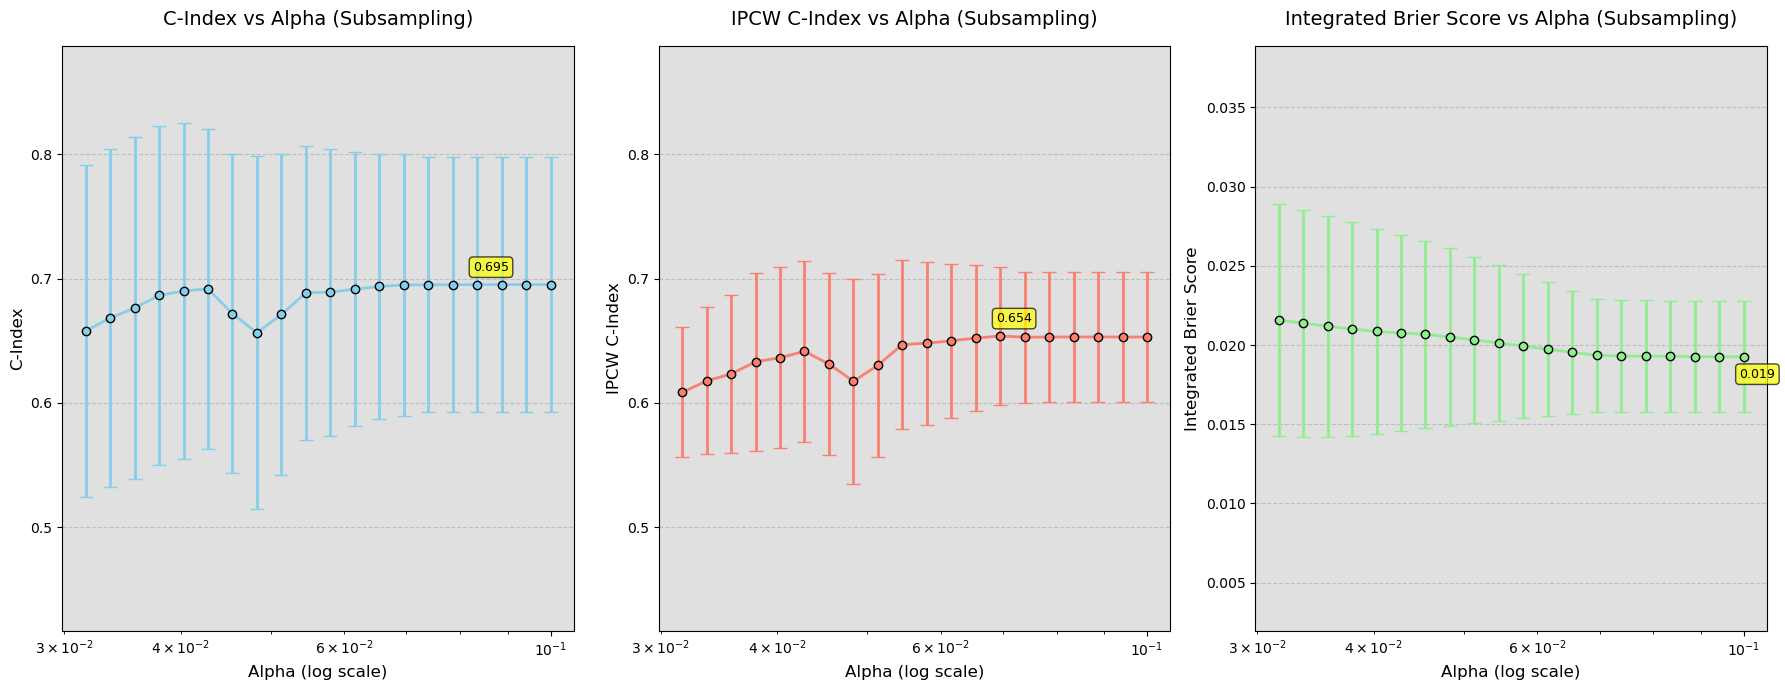

In [ ]:
# Plot the results to visualize alpha performance (ALL SCALING METHODS)
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
fig.patch.set_facecolor('None')
fig.suptitle('Alpha Optimization: All Scaling Methods', fontsize=16, fontweight='bold')

colors = {'no_scaling': 'skyblue', 'standard': 'salmon', 'minmax': 'lightgreen'}
labels = {'no_scaling': 'No Scaling', 'standard': 'Standard Scaling', 'minmax': 'MinMax Scaling'}

# Row 0: C-Index
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[0, idx]
    ax.set_facecolor('#e0e0e0')
    
    summary = alpha_summaries[scaling_name]['c-index']
    
    ax.errorbar(summary['Alpha'], summary['Mean'], 
                yerr=summary['Std'], fmt='o-', capsize=5, color=color, 
                markeredgecolor='black', linewidth=2, markersize=6)
    ax.set_xscale('log')
    ax.set_xlabel('Alpha (log scale)', fontsize=11)
    ax.set_ylabel('C-Index', fontsize=11)
    ax.set_title(f'C-Index: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point
    best_idx = summary['Mean'].idxmax()
    best_alpha = summary.loc[best_idx, 'Alpha']
    best_value = summary.loc[best_idx, 'Mean']
    ax.annotate(f'{best_value:.3f}', 
                xy=(best_alpha, best_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8, ha='center')

# Row 1: IPCW C-Index
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[1, idx]
    ax.set_facecolor('#e0e0e0')
    
    summary = alpha_summaries[scaling_name]['c-index-ipcw']
    
    ax.errorbar(summary['Alpha'], summary['Mean'], 
                yerr=summary['Std'], fmt='o-', capsize=5, color=color,
                markeredgecolor='black', linewidth=2, markersize=6)
    ax.set_xscale('log')
    ax.set_xlabel('Alpha (log scale)', fontsize=11)
    ax.set_ylabel('IPCW C-Index', fontsize=11)
    ax.set_title(f'IPCW C-Index: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point
    best_idx = summary['Mean'].idxmax()
    best_alpha = summary.loc[best_idx, 'Alpha']
    best_value = summary.loc[best_idx, 'Mean']
    ax.annotate(f'{best_value:.3f}', 
                xy=(best_alpha, best_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8, ha='center')

# Row 2: Brier Score
for idx, (scaling_name, color) in enumerate(colors.items()):
    ax = axes[2, idx]
    ax.set_facecolor('#e0e0e0')
    
    summary = alpha_summaries[scaling_name]['int-brier-score']
    
    ax.errorbar(summary['Alpha'], summary['Mean'], 
                yerr=summary['Std'], fmt='o-', capsize=5, color=color,
                markeredgecolor='black', linewidth=2, markersize=6)
    ax.set_xscale('log')
    ax.set_xlabel('Alpha (log scale)', fontsize=11)
    ax.set_ylabel('Integrated Brier Score', fontsize=11)
    ax.set_title(f'Brier Score: {labels[scaling_name]}', fontsize=12, pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Mark best point (minimum for Brier score)
    best_idx = summary['Mean'].idxmin()
    best_alpha = summary.loc[best_idx, 'Alpha']
    best_value = summary.loc[best_idx, 'Mean']
    ax.annotate(f'{best_value:.3f}', 
                xy=(best_alpha, best_value),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=8, ha='center')

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate best alphas on test set
print("=== TEST SET EVALUATION WITH BEST ALPHAS (SUBSAMPLING) ===\n")

# Test set results for each metric's best alpha
test_results = {}

# 1. C-Index best alpha
print("1. Testing C-Index best alpha...")
cindex_best_alpha = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)

# Train model with subsampling using the full training set
X_train_sub, y_train_sub, sub_dataset = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_cindex = CoxnetSurvivalAnalysis(alphas=[cindex_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(X_train_sub, y_train_sub)

# Get test predictions
predicted_risk_cindex = model_cindex.predict(x_test)

# Calculate all metrics for this model
test_cindex = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_cindex)[0]
max_time = min(y_train_sub['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_cindex = concordance_index_ipcw(y_train_sub, y_test, predicted_risk_cindex, tau=max_time)[0]

# Brier score
surv_funcs_cindex = model_cindex.predict_survival_function(x_test)
times = np.array([2*365, 5*365, 10*365])
times = times[times <= max_time]
if len(times) > 0:
    predicted_survival_probs_cindex = np.asarray([[fn(t) for t in times] for fn in surv_funcs_cindex])
    test_brier_cindex = integrated_brier_score(y_train_sub, y_test, predicted_survival_probs_cindex, times)
else:
    test_brier_cindex = np.nan

test_results['c-index_best'] = {
    'alpha': cindex_best_alpha,
    'c-index': test_cindex,
    'c-index-ipcw': test_ipcw_cindex,
    'int-brier-score': test_brier_cindex,
    'n_features': np.sum(model_cindex.coef_.flatten() != 0)
}

print(f"Alpha: {cindex_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_cindex:.4f}")
print(f"Test Brier Score: {test_brier_cindex:.4f}")
print(f"Selected Features: {test_results['c-index_best']['n_features']}")
print("-" * 50)

=== TEST SET EVALUATION WITH BEST ALPHAS (SUBSAMPLING) ===

1. Testing C-Index best alpha...
Best alpha for C-Index: 0.0834
Score: 0.6951 ± 0.1029
Alpha: 0.0834
Test C-Index: 0.6648
Test IPCW C-Index: 0.6681
Test Brier Score: 0.0202
Selected Features: 3
--------------------------------------------------


In [ ]:
# 2. IPCW C-Index best alpha
print("2. Testing IPCW C-Index best alpha...")
ipcw_best_alpha = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)

# Train model with subsampling using the full training set
X_train_sub_ipcw, y_train_sub_ipcw, sub_dataset_ipcw = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_ipcw = CoxnetSurvivalAnalysis(alphas=[ipcw_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(X_train_sub_ipcw, y_train_sub_ipcw)

predicted_risk_ipcw = model_ipcw.predict(x_test)
test_cindex_ipcw = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_ipcw)[0]
max_time_ipcw = min(y_train_sub_ipcw['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_ipcw = concordance_index_ipcw(y_train_sub_ipcw, y_test, predicted_risk_ipcw, tau=max_time_ipcw)[0]

surv_funcs_ipcw = model_ipcw.predict_survival_function(x_test)
times_ipcw = np.array([2*365, 5*365, 10*365])
times_ipcw = times_ipcw[times_ipcw <= max_time_ipcw]
if len(times_ipcw) > 0:
    predicted_survival_probs_ipcw = np.asarray([[fn(t) for t in times_ipcw] for fn in surv_funcs_ipcw])
    test_brier_ipcw = integrated_brier_score(y_train_sub_ipcw, y_test, predicted_survival_probs_ipcw, times_ipcw)
else:
    test_brier_ipcw = np.nan

test_results['ipcw_best'] = {
    'alpha': ipcw_best_alpha,
    'c-index': test_cindex_ipcw,
    'c-index-ipcw': test_ipcw_ipcw,
    'int-brier-score': test_brier_ipcw,
    'n_features': np.sum(model_ipcw.coef_.flatten() != 0)
}

print(f"Alpha: {ipcw_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_ipcw:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_ipcw:.4f}")
print(f"Test Brier Score: {test_brier_ipcw:.4f}")
print(f"Selected Features: {test_results['ipcw_best']['n_features']}")
print("-" * 50)

2. Testing IPCW C-Index best alpha...
Best alpha for IPCW C-Index: 0.0695
Score: 0.6538 ± 0.0558
Alpha: 0.0695
Test C-Index: 0.6653
Test IPCW C-Index: 0.6692
Test Brier Score: 0.0203
Selected Features: 3
--------------------------------------------------
Alpha: 0.0695
Test C-Index: 0.6653
Test IPCW C-Index: 0.6692
Test Brier Score: 0.0203
Selected Features: 3
--------------------------------------------------


In [ ]:
# 3. Brier Score best alpha
print("3. Testing Brier Score best alpha...")
brier_best_alpha = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train model with subsampling using the full training set
X_train_sub_brier, y_train_sub_brier, sub_dataset_brier = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_brier = CoxnetSurvivalAnalysis(alphas=[brier_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(X_train_sub_brier, y_train_sub_brier)

predicted_risk_brier = model_brier.predict(x_test)
test_cindex_brier = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_brier)[0]
max_time_brier = min(y_train_sub_brier['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_brier = concordance_index_ipcw(y_train_sub_brier, y_test, predicted_risk_brier, tau=max_time_brier)[0]

surv_funcs_brier = model_brier.predict_survival_function(x_test)
times_brier = np.array([2*365, 5*365, 10*365])
times_brier = times_brier[times_brier <= max_time_brier]
if len(times_brier) > 0:
    predicted_survival_probs_brier = np.asarray([[fn(t) for t in times_brier] for fn in surv_funcs_brier])
    test_brier_brier = integrated_brier_score(y_train_sub_brier, y_test, predicted_survival_probs_brier, times_brier)
else:
    test_brier_brier = np.nan

test_results['brier_best'] = {
    'alpha': brier_best_alpha,
    'c-index': test_cindex_brier,
    'c-index-ipcw': test_ipcw_brier,
    'int-brier-score': test_brier_brier,
    'n_features': np.sum(model_brier.coef_.flatten() != 0)
}

print(f"Alpha: {brier_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_brier:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_brier:.4f}")
print(f"Test Brier Score: {test_brier_brier:.4f}")
print(f"Selected Features: {test_results['brier_best']['n_features']}")
print("-" * 50)

3. Testing Brier Score best alpha...
Best alpha for Brier Score: 0.1000
Score: 0.0193 ± 0.0035
Alpha: 0.1000
Test C-Index: 0.6673
Test IPCW C-Index: 0.6703
Test Brier Score: 0.0201
Selected Features: 3
--------------------------------------------------
Alpha: 0.1000
Test C-Index: 0.6673
Test IPCW C-Index: 0.6703
Test Brier Score: 0.0201
Selected Features: 3
--------------------------------------------------


In [ ]:
# Create summary table of test results
print("=== SUMMARY OF TEST SET RESULTS (SUBSAMPLING) ===")
test_summary = pd.DataFrame(test_results).T
test_summary.index = ['Best for C-Index', 'Best for IPCW C-Index', 'Best for Brier Score']

# Round for better display
test_summary_display = test_summary.copy()
for col in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    test_summary_display[col] = test_summary_display[col].round(4)
test_summary_display['alpha'] = test_summary_display['alpha'].round(4)

print(test_summary_display)

# Highlight the best performance for each metric
print("\n=== BEST TEST PERFORMANCE BY METRIC (SUBSAMPLING) ===")
print(f"Best C-Index: {test_summary['c-index'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index'].idxmax(), 'alpha']:.4f})")
print(f"Best IPCW C-Index: {test_summary['c-index-ipcw'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index-ipcw'].idxmax(), 'alpha']:.4f})")
print(f"Best Brier Score: {test_summary['int-brier-score'].min():.4f} (Alpha: {test_summary.loc[test_summary['int-brier-score'].idxmin(), 'alpha']:.4f})")

=== SUMMARY OF TEST SET RESULTS (SUBSAMPLING) ===
                        alpha  c-index  c-index-ipcw  int-brier-score  \
Best for C-Index       0.0834   0.6648        0.6681           0.0202   
Best for IPCW C-Index  0.0695   0.6653        0.6692           0.0203   
Best for Brier Score   0.1000   0.6673        0.6703           0.0201   

                       n_features  
Best for C-Index              3.0  
Best for IPCW C-Index         3.0  
Best for Brier Score          3.0  

=== BEST TEST PERFORMANCE BY METRIC (SUBSAMPLING) ===
Best C-Index: 0.6673 (Alpha: 0.1000)
Best IPCW C-Index: 0.6703 (Alpha: 0.1000)
Best Brier Score: 0.0201 (Alpha: 0.1000)


In [ ]:
# Show selected features for each best alpha model
print("=== SELECTED FEATURES BY BEST ALPHA MODELS (SUBSAMPLING) ===\n")

# Get the best alphas
best_alpha_cindex = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
best_alpha_ipcw = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
best_alpha_brier = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train models with best alphas and get selected features
models_features = {}

# 1. C-Index best alpha model
print(f"1. C-INDEX BEST ALPHA MODEL (α = {best_alpha_cindex:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
cindex_features = []
for feature, coef in zip(model_cindex.feature_names_in_, model_cindex.coef_.flatten()):
    if coef != 0:
        cindex_features.append({'feature': feature, 'coefficient': coef})

cindex_features_df = pd.DataFrame(cindex_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index'] = cindex_features_df

print(f"   Number of selected features: {len(cindex_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in cindex_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(cindex_features_df) > 10:
    print(f"     ... and {len(cindex_features_df) - 10} more features")
print()

# 2. IPCW C-Index best alpha model
print(f"2. IPCW C-INDEX BEST ALPHA MODEL (α = {best_alpha_ipcw:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
ipcw_features = []
for feature, coef in zip(model_ipcw.feature_names_in_, model_ipcw.coef_.flatten()):
    if coef != 0:
        ipcw_features.append({'feature': feature, 'coefficient': coef})

ipcw_features_df = pd.DataFrame(ipcw_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index-ipcw'] = ipcw_features_df

print(f"   Number of selected features: {len(ipcw_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in ipcw_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(ipcw_features_df) > 10:
    print(f"     ... and {len(ipcw_features_df) - 10} more features")
print()

# 3. Brier Score best alpha model
print(f"3. BRIER SCORE BEST ALPHA MODEL (α = {best_alpha_brier:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
brier_features = []
for feature, coef in zip(model_brier.feature_names_in_, model_brier.coef_.flatten()):
    if coef != 0:
        brier_features.append({'feature': feature, 'coefficient': coef})

brier_features_df = pd.DataFrame(brier_features).sort_values('coefficient', key=abs, ascending=False)
models_features['int-brier-score'] = brier_features_df

print(f"   Number of selected features: {len(brier_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in brier_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(brier_features_df) > 10:
    print(f"     ... and {len(brier_features_df) - 10} more features")
print()

# Feature overlap analysis
print("=== FEATURE SELECTION OVERLAP ANALYSIS (SUBSAMPLING) ===")
cindex_set = set(cindex_features_df['feature'])
ipcw_set = set(ipcw_features_df['feature'])
brier_set = set(brier_features_df['feature'])

# Common features across all models
common_all = cindex_set & ipcw_set & brier_set
print(f"Features selected by ALL models: {len(common_all)}")
if common_all:
    print(f"   {list(common_all)}")

# Pairwise overlaps
common_cindex_ipcw = cindex_set & ipcw_set
common_cindex_brier = cindex_set & brier_set
common_ipcw_brier = ipcw_set & brier_set

print(f"\nFeatures selected by C-Index AND IPCW models: {len(common_cindex_ipcw)}")
print(f"Features selected by C-Index AND Brier models: {len(common_cindex_brier)}")
print(f"Features selected by IPCW AND Brier models: {len(common_ipcw_brier)}")

# Unique features
unique_cindex = cindex_set - ipcw_set - brier_set
unique_ipcw = ipcw_set - cindex_set - brier_set
unique_brier = brier_set - cindex_set - ipcw_set

print(f"\nFeatures UNIQUE to C-Index model: {len(unique_cindex)}")
print(f"Features UNIQUE to IPCW model: {len(unique_ipcw)}")
print(f"Features UNIQUE to Brier model: {len(unique_brier)}")

=== SELECTED FEATURES BY BEST ALPHA MODELS (SUBSAMPLING) ===

Best alpha for C-Index: 0.0834
Score: 0.6951 ± 0.1029
Best alpha for IPCW C-Index: 0.0695
Score: 0.6538 ± 0.0558
Best alpha for Brier Score: 0.1000
Score: 0.0193 ± 0.0035
1. C-INDEX BEST ALPHA MODEL (α = 0.0834) - SUBSAMPLING:
   Number of selected features: 3
   Selected features (sorted by absolute coefficient value):
     Total administered dose: -0.0279
     Ki67 positive cells (%) at CB: 0.0178
     Age: 0.0156

2. IPCW C-INDEX BEST ALPHA MODEL (α = 0.0695) - SUBSAMPLING:
   Number of selected features: 3
   Selected features (sorted by absolute coefficient value):
     Total administered dose: -0.0282
     Ki67 positive cells (%) at CB: 0.0182
     Age: 0.0163

3. BRIER SCORE BEST ALPHA MODEL (α = 0.1000) - SUBSAMPLING:
   Number of selected features: 3
   Selected features (sorted by absolute coefficient value):
     Total administered dose: -0.0275
     Ki67 positive cells (%) at CB: 0.0174
     Age: 0.0148

=== FEAT